In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from dtaianomaly.visualization import plot_demarcated_anomalies
from dtaianomaly.windowing import compute_window_size, sliding_window

from hydraad import Hydra, SparseScaler, TSBADLoader

In [2]:
def perform_analysis(path: str) -> None:
    # Load data
    dataset = TSBADLoader(path).load()
    X_test = dataset.X_test
    y_test = dataset.y_test

    # Sliding window
    window_size = int(
        np.mean(
            list(
                filter(
                    lambda i: i > 0,
                    [
                        compute_window_size(X_test[:, i], "fft", default_window_size=-1)
                        for i in range(X_test.shape[1])
                    ],
                )
            )
        )
    )
    stride = window_size // 4
    windows = sliding_window(X_test, window_size, stride)
    windows = torch.Tensor(np.expand_dims(windows, 1))

    # Create embedding
    transformer = Hydra(hard_counts=False)
    embedding = transformer.fit_transform(windows)
    embedding_ = SparseScaler().fit_transform(embedding)

    # Plot embedding
    fig, axs = plt.subplots(4, 1, figsize=(20, 15), height_ratios=[1, 3, 2, 2])
    plot_demarcated_anomalies(X_test, y_test, figsize=(20, 3), ax=axs[0])
    axs[0].set_xlim(0, X_test.shape[0])
    axs[1].imshow(embedding_.T, aspect="auto", cmap="gist_gray_r")
    axs[2].plot(embedding_)
    axs[2].set_xlim(0, embedding_.shape[0])

    qs = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    for q in qs:
        axs[3].plot(torch.quantile(embedding_.abs(), q, dim=1), label=f"q={q}")
    axs[3].set_xlim(0, embedding_.shape[0])
    plt.legend(
        loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=len(qs), frameon=False
    )

    fig.suptitle(f"Time series with {X_test.shape[1]} attributes")
    fig.tight_layout()

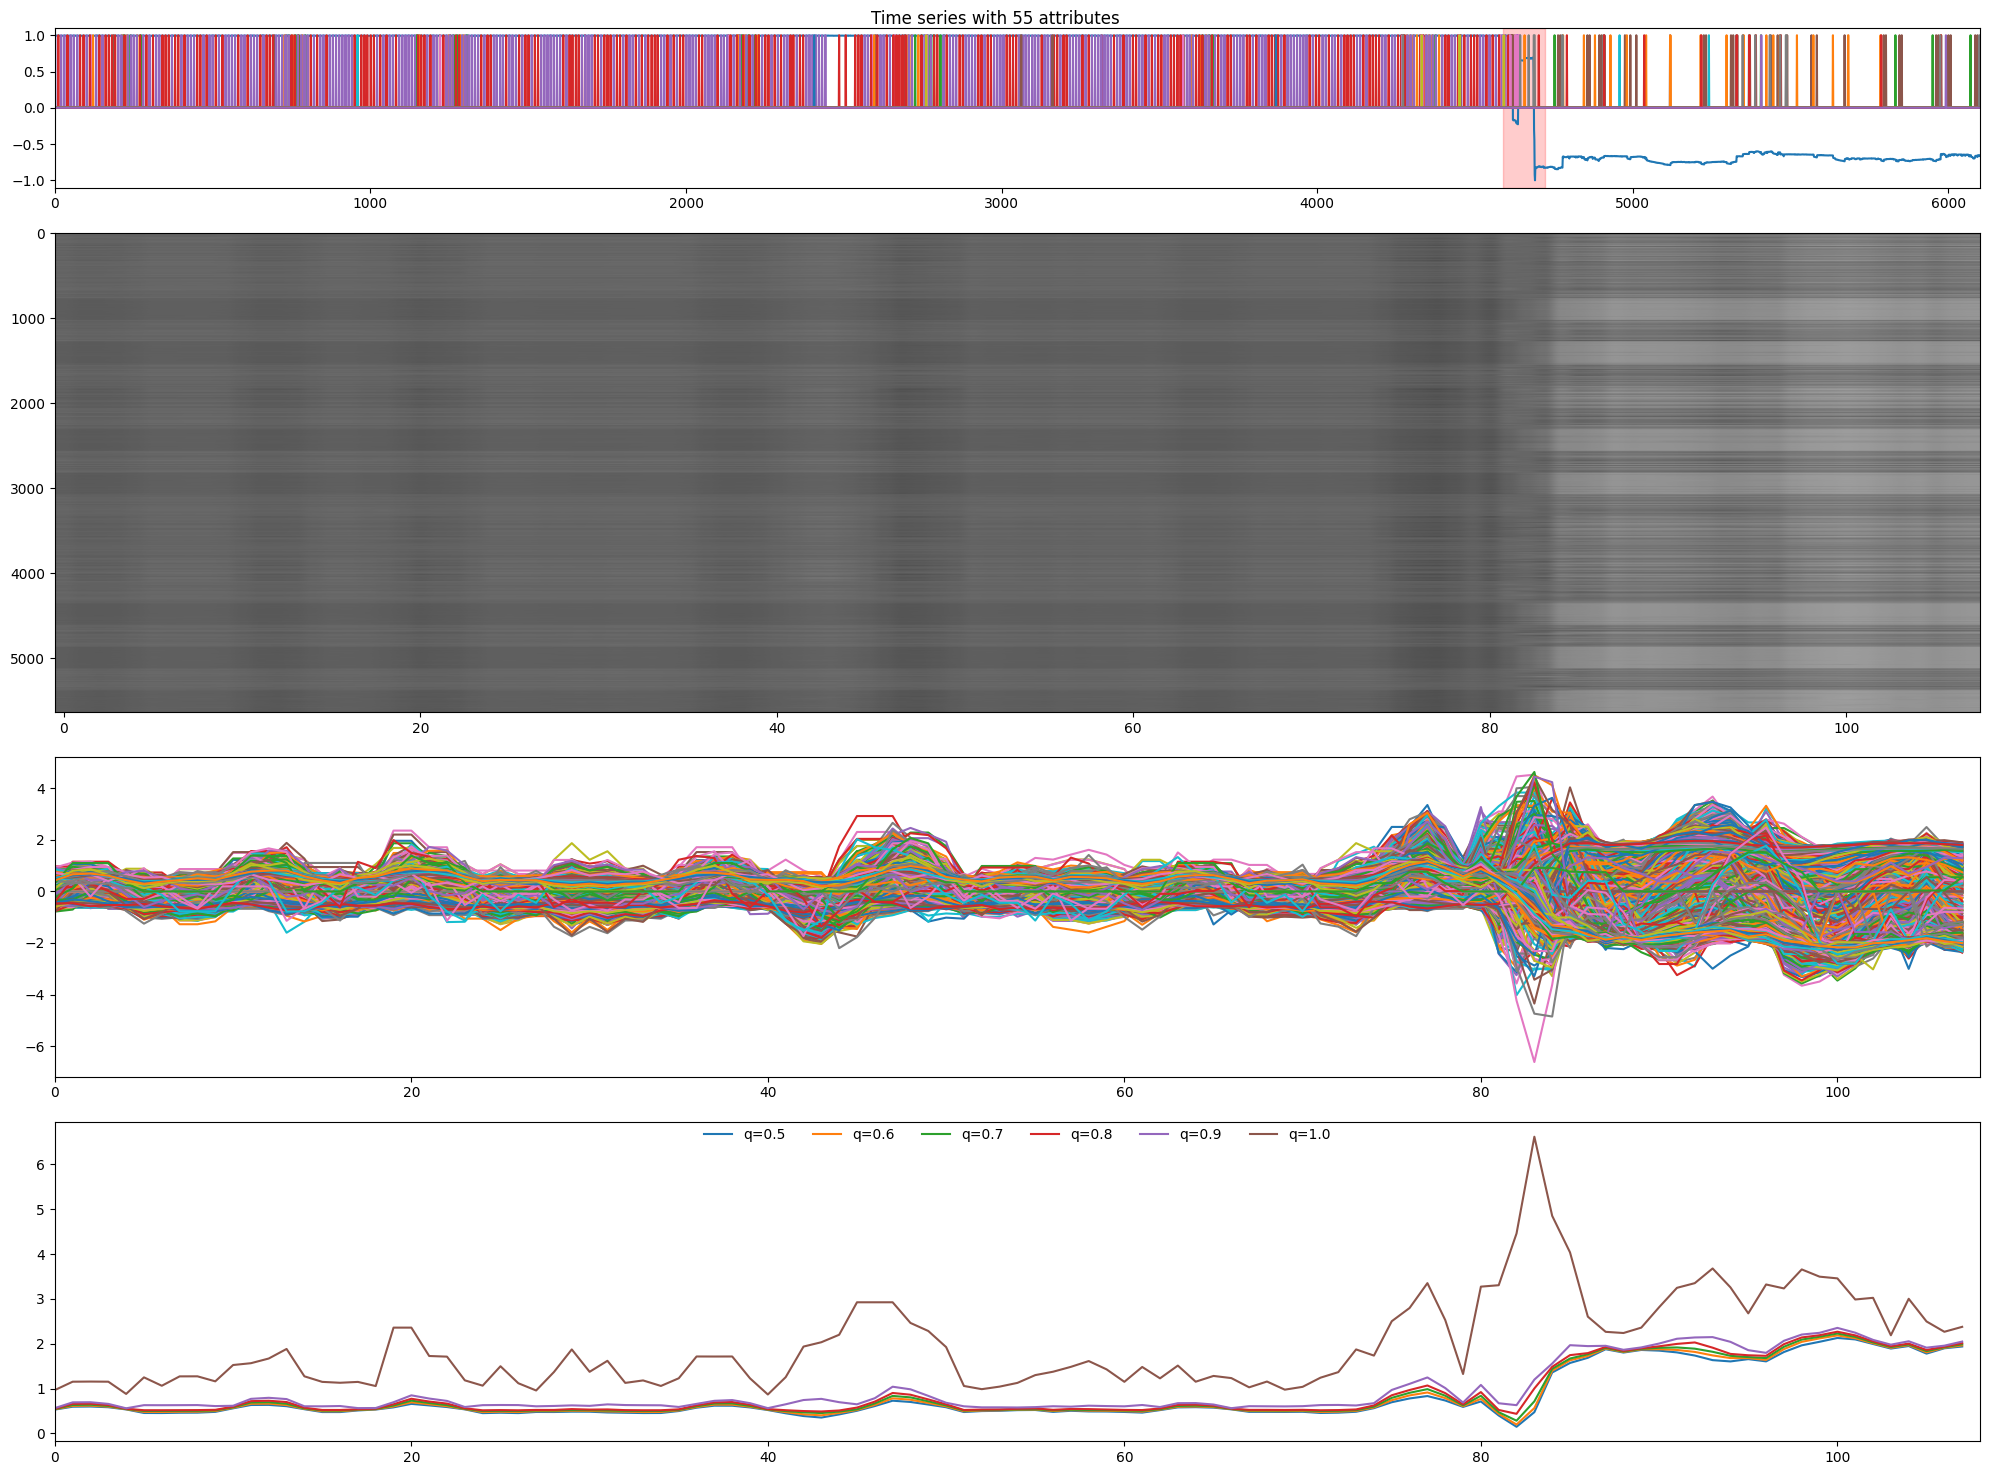

In [3]:
perform_analysis("../data/TSB-AD-M/011_MSL_id_10_Sensor_tr_1525_1st_4590.csv")

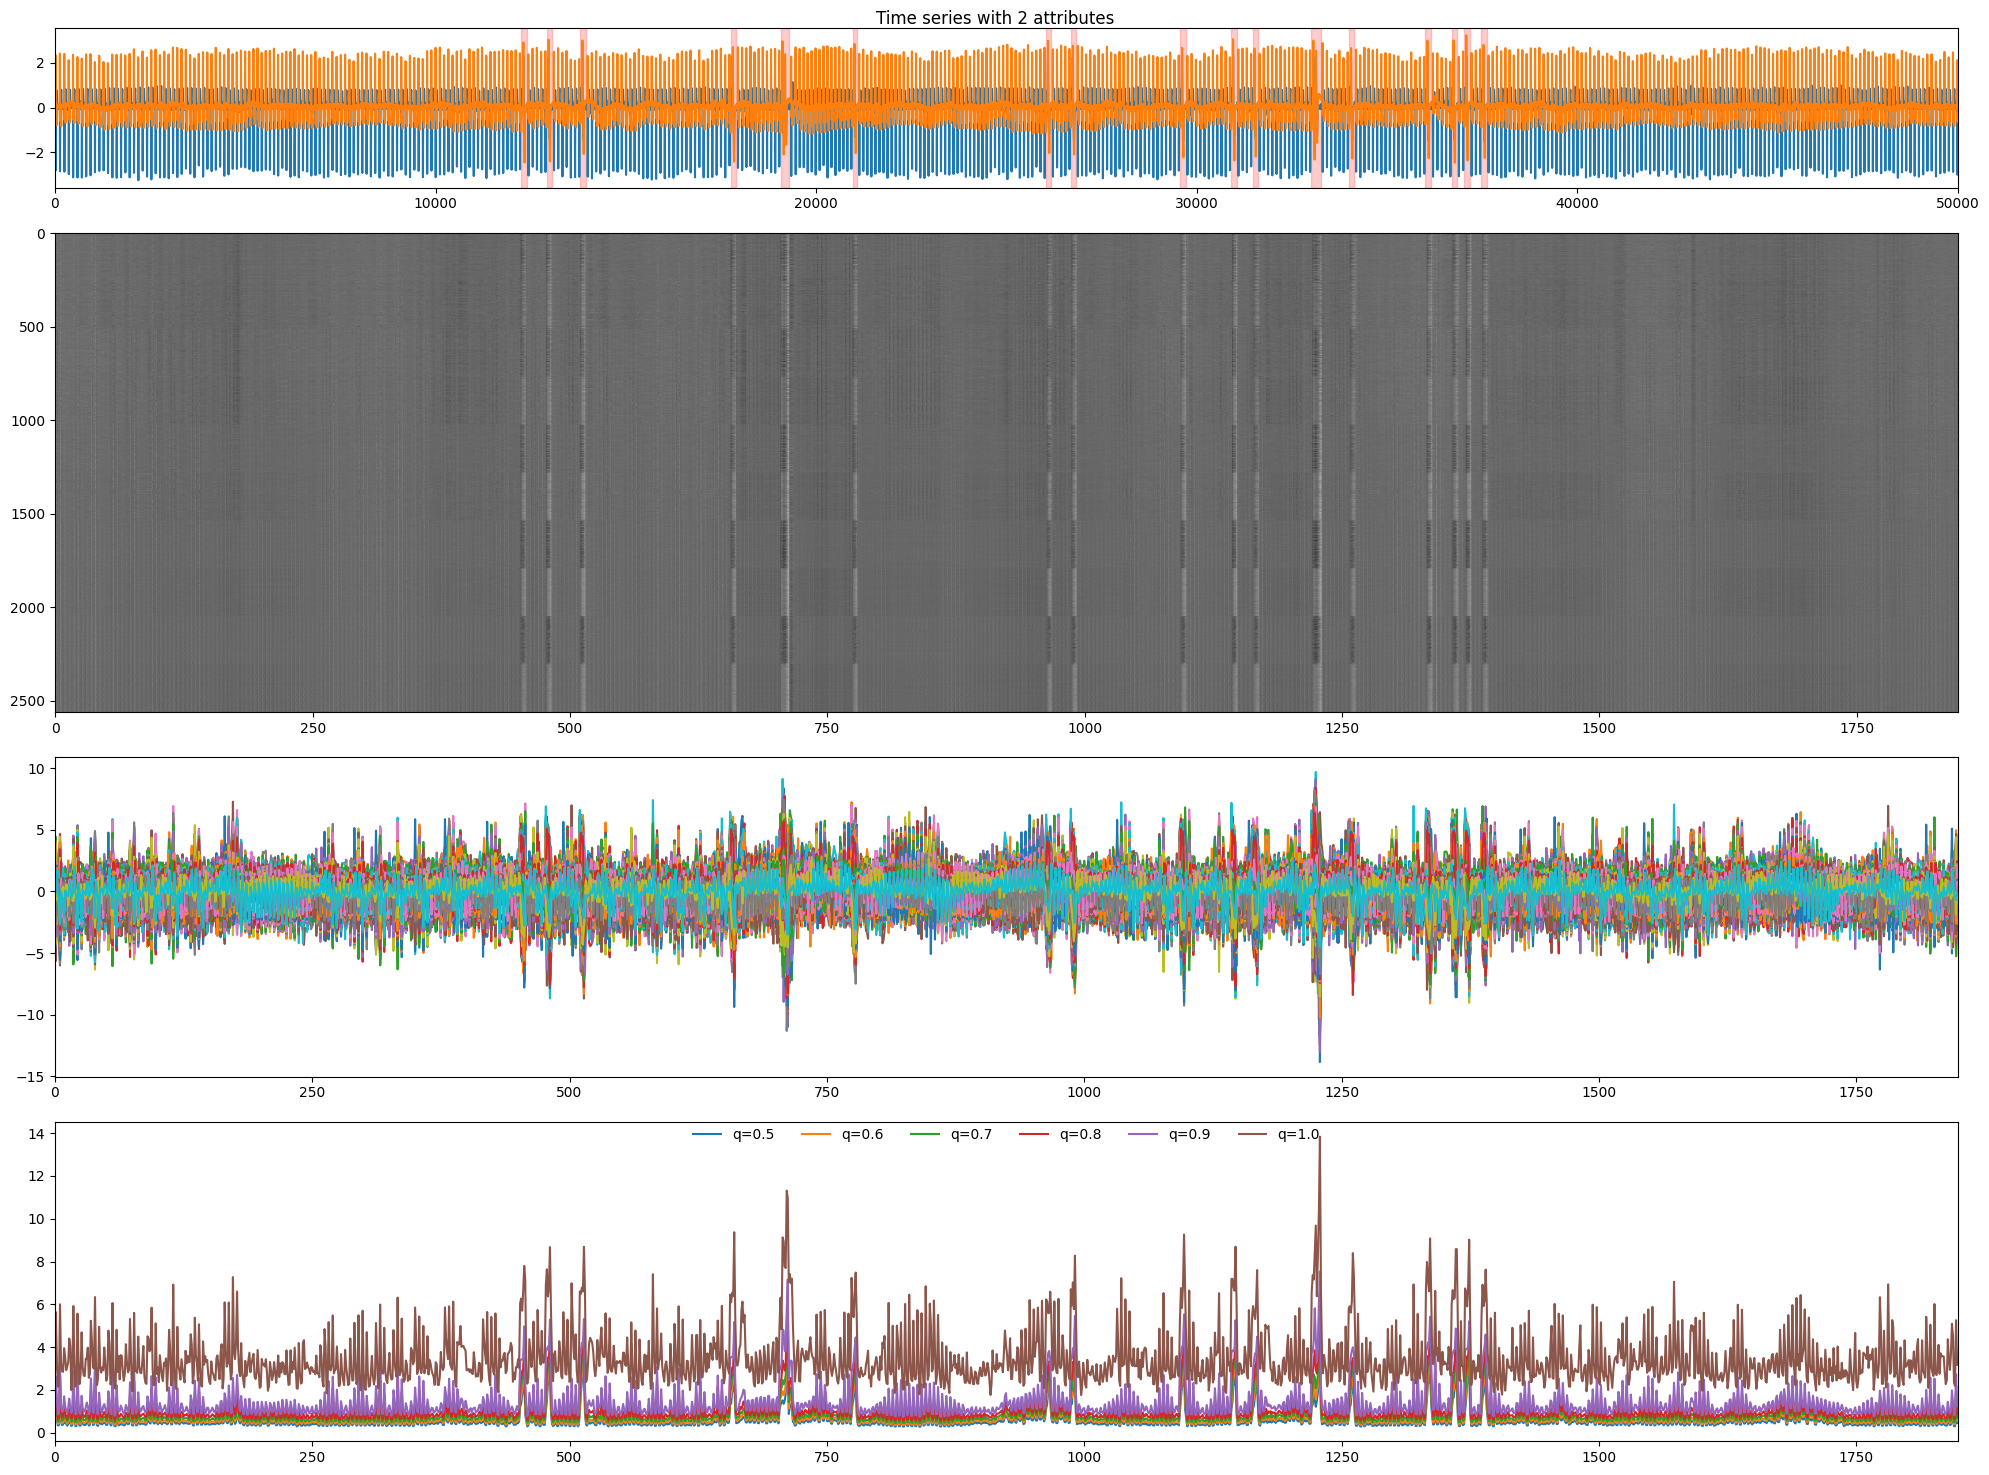

In [4]:
perform_analysis("../data/TSB-AD-M/090_SVDB_id_7_Medical_tr_12157_1st_12257.csv")